# Introduction




# Prepare for analysis

## Load packages

In [1]:
from titanic.data import (
    load_data,
    quick_glimpse,
    missing_data_summary,
    most_frequent_summary,
    unique_values_summary,
    combine_train_test,
)
from titanic.features import (
    add_family_size,
    add_age_interval,
    add_fare_interval,
    add_sex_pclass,
    add_name_parts,
    add_family_type,
    add_titles,
    survival_by_title_and_sex,
    map_sex_to_numeric,
)
from titanic.plotting import (
    plot_count_pairs,
    plot_distribution_pairs,
)
from titanic.model import (
    split_train_valid,
    get_features_and_target,
    train_random_forest,
    print_classification_report,
)

## Read the data

In [2]:
train_df, test_df = load_data()

# Preliminary data inspection

## Quick glimpse of the data

In [3]:
quick_glimpse(train_df)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
quick_glimpse(test_df)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


## Few statistics on the data

### Missing data

In [5]:
missing_data_summary(train_df)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,0,177,0,0,0,0,687,2
Percent,0.0,0.0,0.0,0.0,0.0,19.86532,0.0,0.0,0.0,0.0,77.104377,0.224467
Types,int64,int64,int64,str,str,float64,int64,int64,str,float64,str,str


In [6]:
missing_data_summary(test_df)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,86,0,0,0,1,327,0
Percent,0.0,0.0,0.0,0.0,20.574163,0.0,0.0,0.0,0.239234,78.229665,0.0
Types,int64,int64,str,str,float64,int64,int64,str,float64,str,str


### Most frequent data

In [7]:
most_frequent_summary(train_df)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Most frequent item,1,0,3,"Braund, Mr. Owen Harris",male,24.0,0,0,347082,8.05,G6,S
Frequence,1,549,491,1,577,30,608,678,7,43,4,644
Percent from total,0.112,61.616,55.107,0.112,64.759,4.202,68.238,76.094,0.786,4.826,1.961,72.441


In [8]:
most_frequent_summary(test_df)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Most frequent item,892,3,"Kelly, Mr. James",male,21.0,0,0,PC 17608,7.75,B57 B59 B63 B66,S
Frequence,1,218,1,266,17,283,324,5,21,3,270
Percent from total,0.239,52.153,0.239,63.636,5.12,67.703,77.512,1.196,5.036,3.297,64.593


### Unique values

In [9]:
unique_values_summary(train_df)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Uniques,891,2,3,891,2,88,7,7,681,248,147,3


In [10]:
unique_values_summary(test_df)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Uniques,418,3,418,2,79,7,8,363,169,76,3


# Exploratory data analysis

## Univariate analysis for all features


We show here two graphs in paralel:
* distribution of class values, split per Survived value
* comparison of class values, in train and test data


Let's first aggregate train and test data into one single dataframe, `all_df`.

In [11]:
all_df = combine_train_test(train_df, test_df)

In [12]:
all_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train


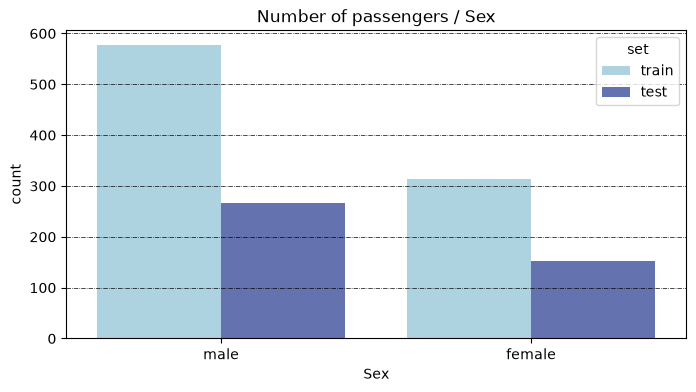

In [13]:
# Plot count pairs "Sex"
plot_count_pairs(all_df, "Sex")

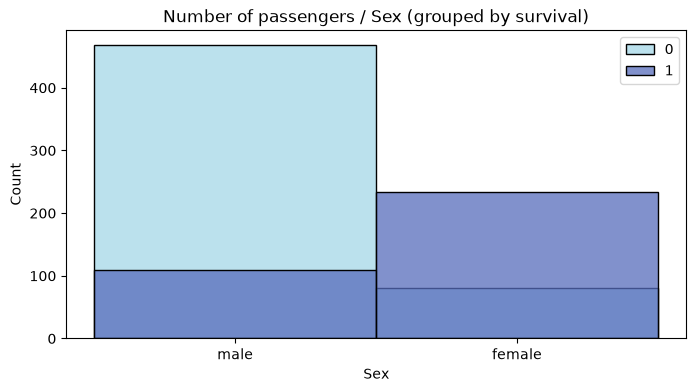

In [14]:
# Plot distribution pairs for "Sex" and hue as "Survived"
plot_distribution_pairs(
    train_df, "Sex", title="Sex (grouped by survival)", hue="Survived"
)

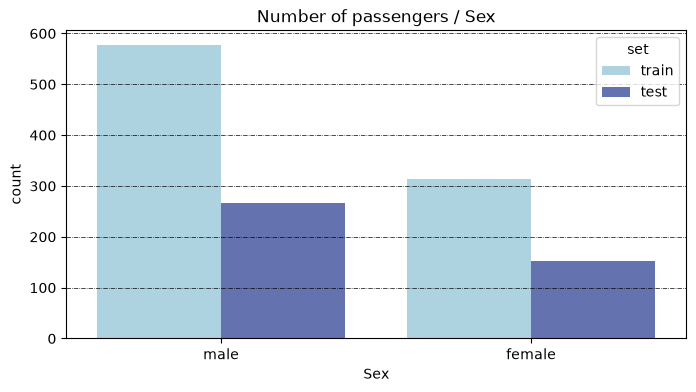

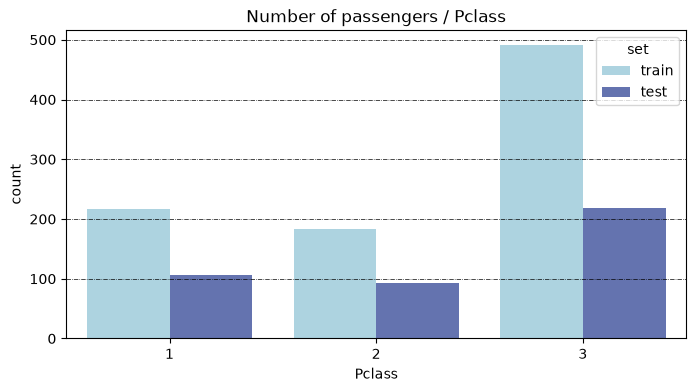

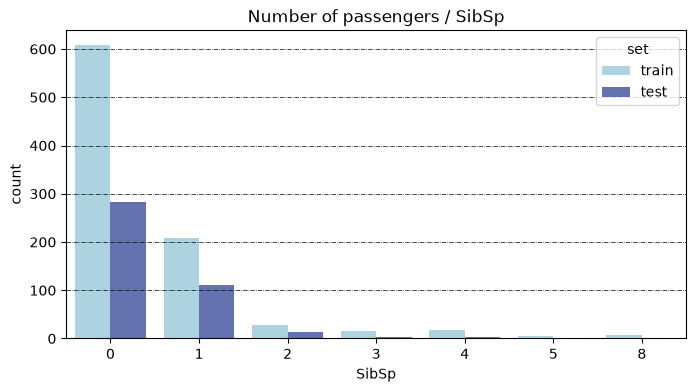

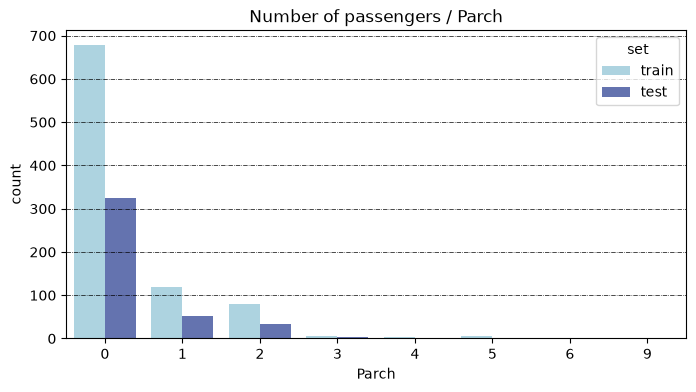

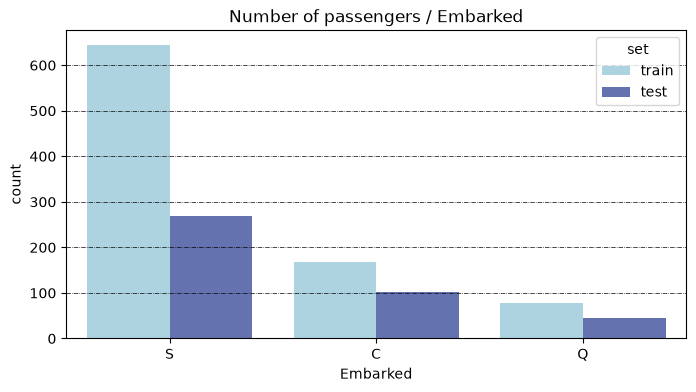

In [15]:
# Plot count pairs using all_df for the columns: Sex, Pclasss, SibSp, Parch, Embarked
for feature in ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]:
    plot_count_pairs(all_df, feature)

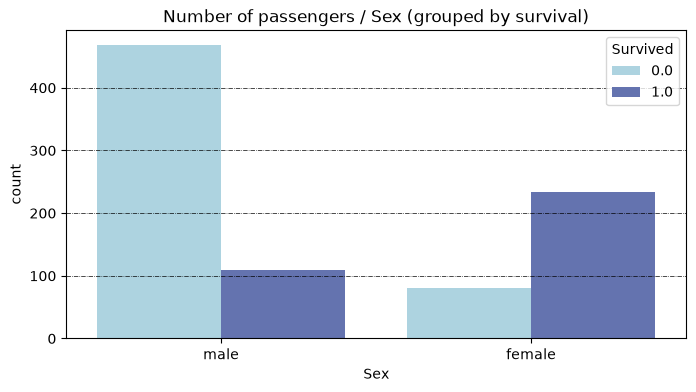

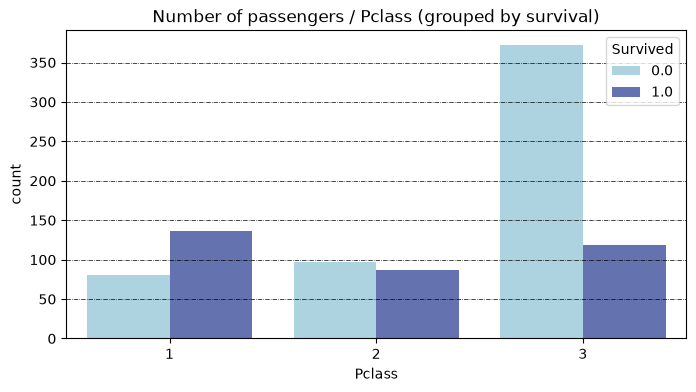

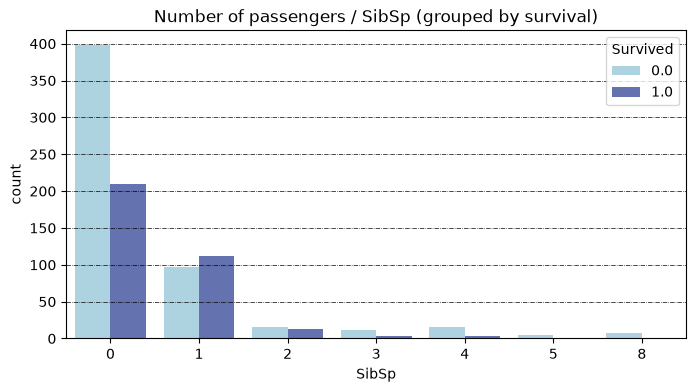

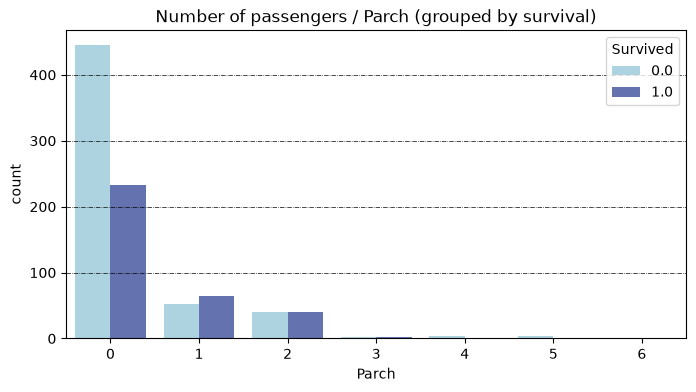

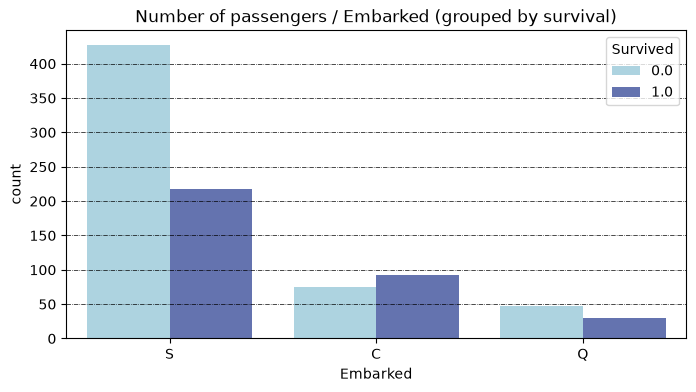

In [16]:
# Plot count pairs using all_df for the columns: Sex, Pclasss, SibSp, Parch, Embarked and use "Survived" as hue.
for feature in ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]:
    plot_count_pairs(
        all_df, feature, title=f"{feature} (grouped by survival)", hue="Survived"
    )

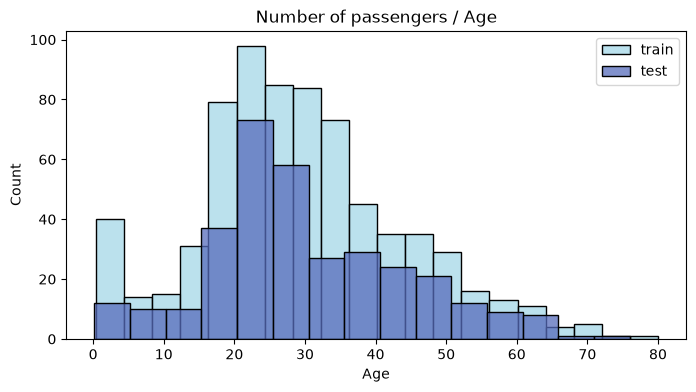

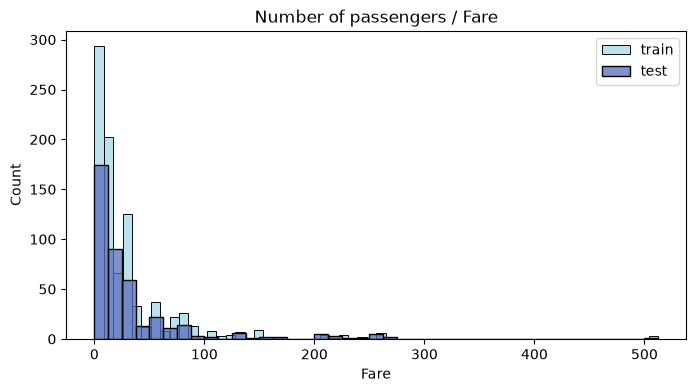

In [17]:
# Plot distribution pairs for Age and Fare
for feature in ["Age", "Fare"]:
    plot_distribution_pairs(all_df, feature)

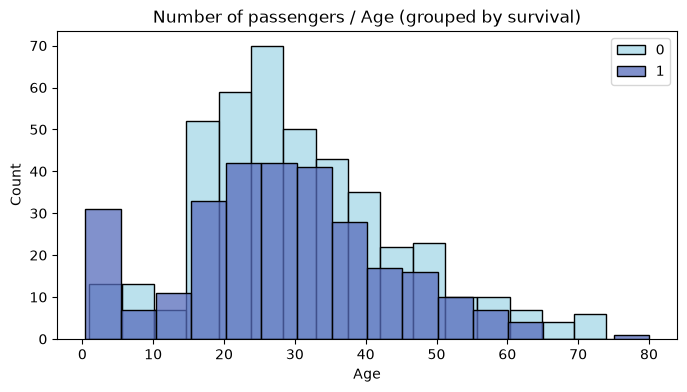

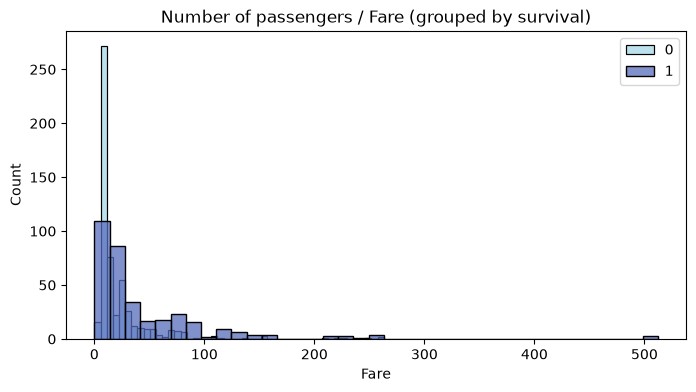

In [18]:
# Plot distribution pairs for Age and Fare using "Survived" as hue
for feature in ["Age", "Fare"]:
    plot_distribution_pairs(
        train_df, feature, title=f"{feature} (grouped by survival)", hue="Survived"
    )

## Family size


Based on SibSp (sibilings or spouse) and Parch (parents or children), we set the Family Size field.

In [19]:
all_df = add_family_size(all_df)

In [20]:
train_df = add_family_size(train_df)

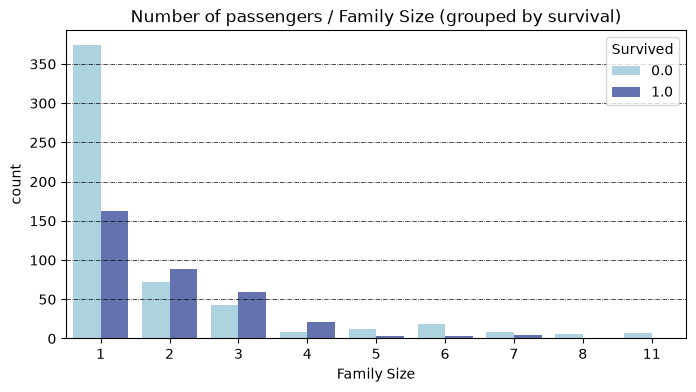

In [21]:
# Plot count pairs using all_df for the column "Family Size" and use "Survived" as hue.
plot_count_pairs(
    all_df, "Family Size", title="Family Size (grouped by survival)", hue="Survived"
)

## Age interval

In [22]:
all_df = add_age_interval(all_df)

In [23]:
train_df = add_age_interval(train_df)

In [24]:
all_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set,Family Size,Age Interval
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train,2,1.0
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train,2,2.0
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train,1,1.0
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train,2,2.0
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train,1,2.0


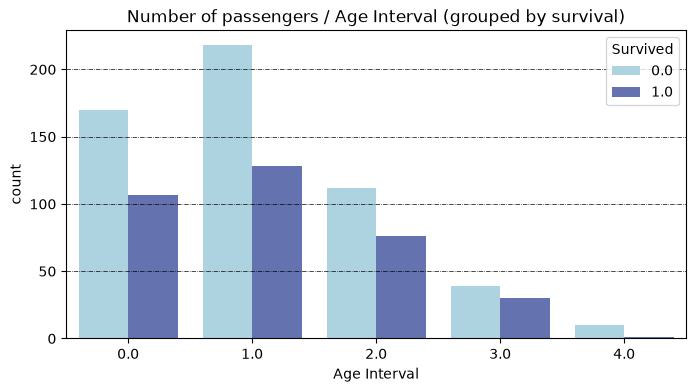

In [25]:
# Plot count pairs using all_df for the column "Age Interval" and use "Survived" as hue.
plot_count_pairs(
    all_df, "Age Interval", title="Age Interval (grouped by survival)", hue="Survived"
)

## Fare interval

In [26]:
all_df = add_fare_interval(all_df)

In [27]:
train_df = add_fare_interval(train_df)

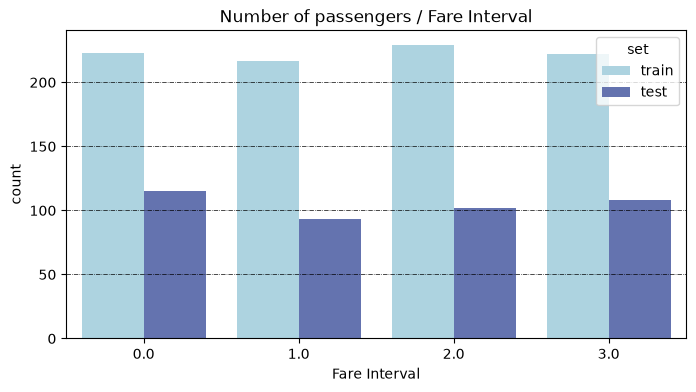

In [28]:
# Plot count pairs using all_df for the column "Fare Interval"
plot_count_pairs(all_df, "Fare Interval")

Let's create a composed feature: Pclass + Sex.

In [29]:
train_df = add_sex_pclass(train_df)

In [30]:
all_df = add_sex_pclass(all_df)

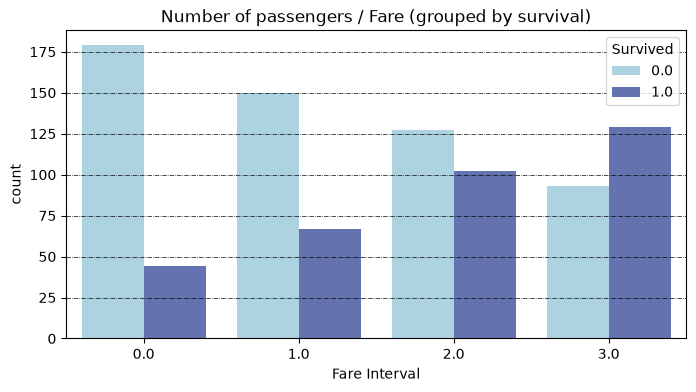

In [31]:
# Plot count pairs using all_df for the column "Fare Interval" and "Fare (grouped by survival)" with "Survived" as hue
plot_count_pairs(
    all_df, "Fare Interval", title="Fare (grouped by survival)", hue="Survived"
)

## Process names


When we process names, we would like to extract the following information:

- Family name - this is the first word (or few first words, if a family name with multiple names), followed by a comma  
- Title - this follows just after the comma   
- Given name - this is the word or group of words following family name  
- Maiden name - for ladies, is given between parantheses  

We start with creating a function that parses the Name string and extract (if possible) these 4 elements


In [32]:
all_df = add_name_parts(all_df)

In [33]:
train_df = add_name_parts(train_df)

## Multivariate analysis


Let's look now to the interaction of multiple features.

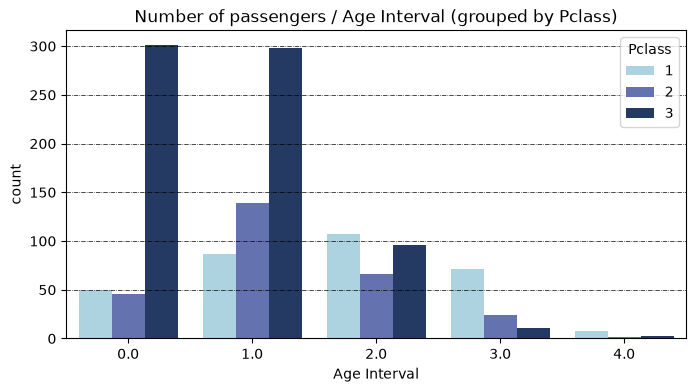

In [34]:
# Plot count pairs of "Age Interval" grouped by "Pclass"
plot_count_pairs(
    all_df, "Age Interval", title="Age Interval (grouped by Pclass)", hue="Pclass"
)

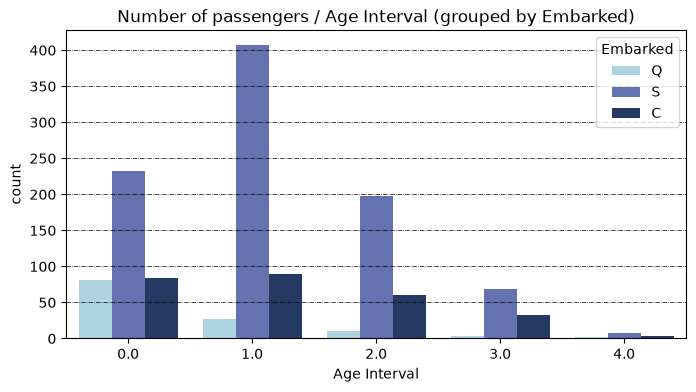

In [35]:
# Plot count pairs of "Age Interval" grouped by "Embarked"
plot_count_pairs(
    all_df, "Age Interval", title="Age Interval (grouped by Embarked)", hue="Embarked"
)

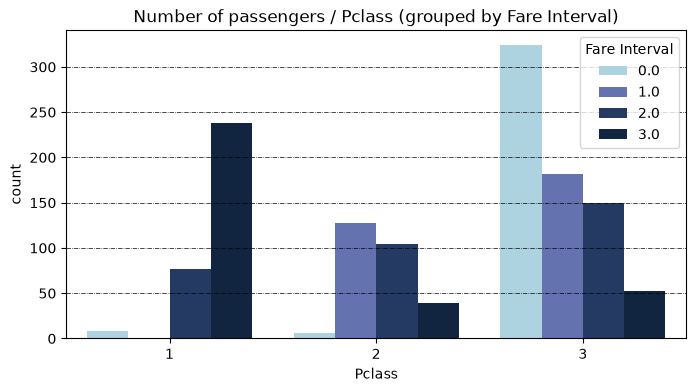

In [36]:
# Plot count pairs of "Pclass" grouped by "Fare Interval"
plot_count_pairs(
    all_df, "Pclass", title="Pclass (grouped by Fare Interval)", hue="Fare Interval"
)

### Few more engineered data 


Let's create two more engineered features:  
* Family size interval: Single, Small, Large  
* Aggregated titles: Mr, Mrs, Master, Miss, and Rare  

In [37]:
all_df = add_family_type(all_df)
train_df = add_family_type(train_df)

In [38]:
all_df = add_titles(all_df)
train_df = add_titles(train_df)

In [39]:
survival_by_title_and_sex(train_df)

,Titles,Sex,Survived
0,Master.,male,0.575000
1,Miss.,female,0.702703
2,Mr.,male,0.156673
3,Mrs.,female,0.793651
4,Rare,female,1.000000
5,Rare,male,0.250000


# Baseline model

## Feature engineering: Map categorical value to numerical values

In [40]:
train_df = map_sex_to_numeric(train_df)
test_df = map_sex_to_numeric(test_df)

Create train-validation split.

In [41]:
train, valid = split_train_valid(train_df)

Define predictor features and target feature.

In [42]:
predictors = ["Sex", "Pclass"]
target = "Survived"

Define the training and validation data and labels.

In [43]:
train_X, train_Y = get_features_and_target(train, predictors, target)
valid_X, valid_Y = get_features_and_target(valid, predictors, target)

Train a random forest classifier on the training data.

In [44]:
clf = train_random_forest(train_X, train_Y)

Predict the train data (to check the training classification error).

In [45]:
preds_tr = clf.predict(train_X)

Predict the validation data.

In [46]:
preds = clf.predict(valid_X)

# Evaluation

## Classification report for training data.

In [47]:
print_classification_report(train_Y, preds_tr)

              precision    recall  f1-score   support

Not Survived       0.75      0.99      0.86       444
    Survived       0.96      0.47      0.63       268

    accuracy                           0.79       712
   macro avg       0.86      0.73      0.74       712
weighted avg       0.83      0.79      0.77       712



Classification report for validation data.

In [48]:
print_classification_report(valid_Y, preds)

              precision    recall  f1-score   support

Not Survived       0.73      0.96      0.83       105
    Survived       0.90      0.49      0.63        74

    accuracy                           0.77       179
   macro avg       0.81      0.72      0.73       179
weighted avg       0.80      0.77      0.75       179

